# Renewable Electricity, Income and Access to Electricity: Evidence from Countries Worldwide, with Kenya as a Case

## The real-world problem
Countries must decide how to expand electricity for their people. They need
power that is affordable, reliable, and clean. It is not always clear whether
a higher renewable share goes together with higher income or better access.

## Why it matters
Electricity access supports schools, clinics, and businesses. Energy planners
and governments, including in Kenya, make long-term investment choices.

## Research question
Across countries and years, is a higher share of electricity from renewable
sources associated with higher GDP per capita and higher access to electricity?

## Who is affected
Energy ministries, development agencies, investors, and households that
depend on electricity.

## Decision the findings could support
Which energy investments fit a country's stage of income and electricity access.

## Initial hypothesis (written before analysing the data)
I expect that countries with higher GDP per capita have higher access to
electricity. I am not sure about renewable share, so I will test whether it is
higher or lower in richer countries.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

energy = pd.read_csv("C:\\Users\\Admin\\Desktop\\Python-class\\kenya-energy-income\\data\\raw\\owid-energy-data.csv")
wb = pd.read_csv("C:\\Users\\Admin\\Desktop\\Python-class\\kenya-energy-income\\data\\raw\\world_bank_indicators.csv")

The OWID energy data

In [4]:
energy_cols = ["country", "year", "iso_code", "population", "gdp",
               "renewables_share_elec", "electricity_generation",
               "per_capita_electricity"]
oe = energy[energy_cols]

print(oe.head())                      # first 5 rows
print(energy.shape)                   # rows, columns
oe.info()                             # column types and non-empty counts
print(oe.isna().sum())                # missing values per column
print("Duplicate country-year rows:", energy.duplicated(subset=["country", "year"]).sum())
print(oe.describe())                  # summary statistics
print("Years:", energy["year"].min(), "to", energy["year"].max())

         country  year iso_code  population  gdp  renewables_share_elec  \
0  ASEAN (Ember)  2000      NaN         NaN  NaN                 19.347   
1  ASEAN (Ember)  2001      NaN         NaN  NaN                 19.066   
2  ASEAN (Ember)  2002      NaN         NaN  NaN                 17.664   
3  ASEAN (Ember)  2003      NaN         NaN  NaN                 16.672   
4  ASEAN (Ember)  2004      NaN         NaN  NaN                 15.700   

   electricity_generation  per_capita_electricity  
0                  378.61                     NaN  
1                  404.85                     NaN  
2                  433.19                     NaN  
3                  458.24                     NaN  
4                  496.56                     NaN  
(23195, 130)
<class 'pandas.DataFrame'>
RangeIndex: 23195 entries, 0 to 23194
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   country         

### Cell 2: Understanding the OWID energy dataset

**What I did:** I loaded the Our World in Data energy file and looked at the
first rows, the size, the data types, the missing values, and the duplicates.
I also calculated summary statistics for eight key columns.

**What I found:**
- The file has 23,195 rows and 130 columns. I looked at 8 of those columns.
- There are no duplicate country-year rows, so each country appears once per year.
- Some rows are regions, such as "ASEAN (Ember)", and not countries. They have
  no ISO code. 6,096 rows have no ISO code, so I must remove them in the
  data preparation phase.
- Renewables share of electricity has only 7,943 values out of 23,195 rows.
  This means any test using it can use at most 7,943 rows.
- Renewables share has a mean of 30.1 and a median of 18.6. The mean is higher
  than the median, which means the data leans to the right: a few countries
  have very high shares.

**How this helps my research question:** I need to compare renewable share with
income and electricity access. Because renewable data is missing for many
rows, I know the tests will use fewer rows than the full joined dataset. I will
state this as a limitation.

The World Bank data

In [5]:
print(wb.head())
print(wb.shape)
wb.info()
print(wb.isna().sum())
print("Duplicate country-year rows:", wb.duplicated(subset=["Country Code", "Year"]).sum())
print(wb.describe())
print("Years:", wb["Year"].min(), "to", wb["Year"].max())

  Country Name Country Code  Year  \
0        Aruba          ABW  1960   
1        Aruba          ABW  1961   
2        Aruba          ABW  1962   
3        Aruba          ABW  1963   
4        Aruba          ABW  1964   

   GDP per capita (constant 2015 US$) [NY.GDP.PCAP.KD]  \
0                                                NaN     
1                                                NaN     
2                                                NaN     
3                                                NaN     
4                                                NaN     

   GDP per capita, PPP (constant 2021 international $) [NY.GDP.PCAP.PP.KD]  \
0                                                NaN                         
1                                                NaN                         
2                                                NaN                         
3                                                NaN                         
4                                     

### Cell 3: Understanding the World Bank dataset

**What I did:** I loaded the World Bank indicators file and checked its
size, data types, missing values, duplicates, and summary statistics.

**What I found:**
- The file has 17,556 rows and 11 columns, covering 1960 to 2025.
- There are no duplicate country-year rows.
- All indicator columns are numeric, so I do not need to change data types.
- Access to electricity has values in only 8,122 rows. GDP per capita
  (constant 2015 US$) has 14,561 values, so it is more complete.
- The file probably contains regions and income groups as well as countries,
  because 17,556 rows divided by 66 years gives 266 entities.
  I will check this and remove the groups in data preparation.

**How this helps my research question:** I need GDP per capita and electricity
access from this file. Both are available for thousands of country-years, but
electricity access has more gaps. I will say this in my limitations.

Central tendency and spread

In [6]:
gdp = "GDP per capita (constant 2015 US$) [NY.GDP.PCAP.KD]"
acc = "Access to electricity (% of population) [EG.ELC.ACCS.ZS]"

stats = pd.DataFrame({
    "renewables_share_elec": pd.to_numeric(energy["renewables_share_elec"], errors="coerce"),
    "gdp_per_capita": pd.to_numeric(wb[gdp], errors="coerce"),
    "electricity_access": pd.to_numeric(wb[acc], errors="coerce"),
})

summary = stats.agg(["mean", "median", "std", "min", "max", "skew"]).T
summary["IQR"] = stats.quantile(0.75) - stats.quantile(0.25)
print(summary)

                               mean       median           std         min  \
renewables_share_elec     30.096831    18.602000     30.633735    0.000000   
gdp_per_capita         11375.073071  3759.607897  18164.135952  122.678901   
electricity_access        81.465540    98.613616     28.181642    0.533899   

                                 max      skew           IQR  
renewables_share_elec     100.000000  0.918867     47.172500  
gdp_per_capita         247170.103807  3.314803  11999.865659  
electricity_access        100.000000 -1.407661     29.691354  


### Cell 4: Central tendency and spread

**What I did:** I calculated the mean, median, standard deviation, minimum,
maximum, skewness, and IQR for renewables share, GDP per capita, and
electricity access.

**What I found:**
- GDP per capita has a mean of 11,375 but a median of 3,760. Skewness is
  3.31, so the data is strongly right-skewed. A few very rich cases pull the
  average up, so the median describes a typical case better.
- Electricity access has a mean of 81.5 but a median of 98.6, and skewness
  of -1.41. Many country-years are close to 100%, and a smaller group is far
  below.
- Renewables share has a mean of 30.1, a median of 18.6, and skewness of 0.92.

**Important note:** These numbers still include regions and groups, which are
not countries. I will recalculate them after cleaning.

**How this helps my research question:** Because the data is skewed, I will
look at the median and use methods that are not distorted by a few extreme
values, such as a log scale for GDP and Spearman correlation.

Histograms and a boxplot

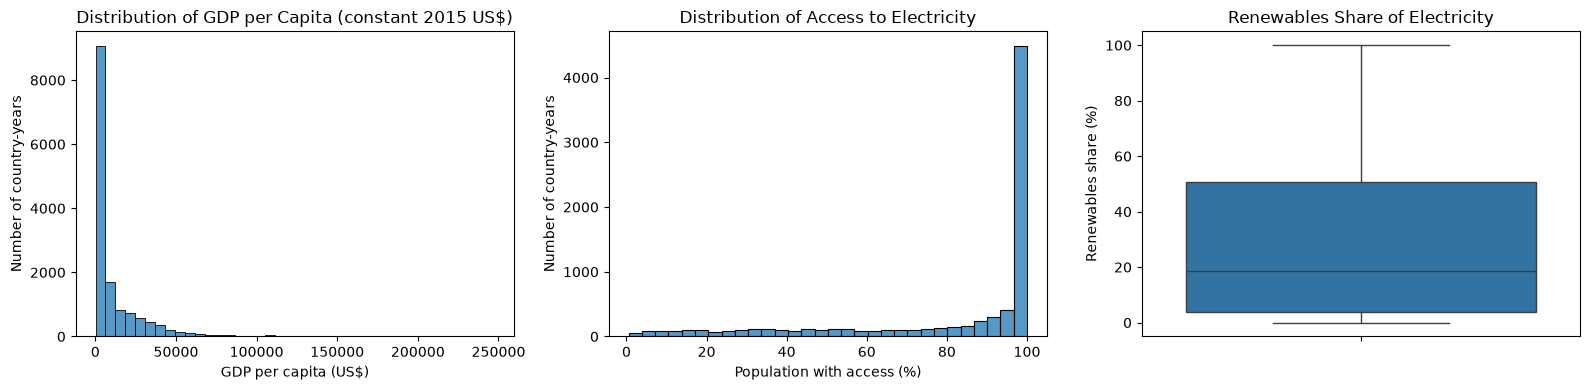

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(stats["gdp_per_capita"].dropna(), bins=40, ax=axes[0])
axes[0].set_title("Distribution of GDP per Capita (constant 2015 US$)")
axes[0].set_xlabel("GDP per capita (US$)")
axes[0].set_ylabel("Number of country-years")

sns.histplot(stats["electricity_access"].dropna(), bins=30, ax=axes[1])
axes[1].set_title("Distribution of Access to Electricity")
axes[1].set_xlabel("Population with access (%)")
axes[1].set_ylabel("Number of country-years")

sns.boxplot(y=stats["renewables_share_elec"].dropna(), ax=axes[2])
axes[2].set_title("Renewables Share of Electricity")
axes[2].set_ylabel("Renewables share (%)")

plt.tight_layout()
plt.show()

### Cell 5: Distributions of the key variables

**What I did:** I drew two histograms (GDP per capita and access to
electricity) and one boxplot (renewables share of electricity).

**What the charts show:**
- GDP per capita: most country-years are at low values, with a long thin tail
  to about 250,000. The distribution is strongly right-skewed.
- Access to electricity: a very tall bar at 100%, about 4,500 country-years,
  and a flatter spread below it. Many country-years already have full access.
- Renewables share: the median is about 19, the middle half of values runs
  from about 4 to about 51, and values reach both 0 and 100. Countries differ
  widely.

**Conclusion:** The data is not symmetrical, so the mean can mislead. I will
use medians, a log scale for GDP per capita, and correlation methods that do
not depend on a straight-line pattern. These charts still include regions, so
I will redraw them after cleaning.

Where is Kenya?

In [8]:
print("OWID rows for Kenya:", (energy["iso_code"] == "KEN").sum())
print("World Bank rows for Kenya:", (wb["Country Code"] == "KEN").sum())

OWID rows for Kenya: 45
World Bank rows for Kenya: 66


### Cell 6: Checking that Kenya is in both datasets

**What I did:** I counted the rows for Kenya (ISO code KEN) in each file.

**What I found:** OWID has 45 rows for Kenya and the World Bank has 66.

**What this means:** Kenya is in both datasets, so I can use it as a case
study. After joining, Kenya can have at most 45 rows, so I will use Kenya to
illustrate the findings and not to draw statistical conclusions.

It tells us how usable the renewables data is for real countries:

In [9]:
countries = energy[energy["iso_code"].notna()]
r = countries[countries["renewables_share_elec"].notna()]
print("Rows:", len(r))
print("Years:", r["year"].min(), "to", r["year"].max())
print("Countries:", r["iso_code"].nunique())

Rows: 6330
Years: 1985 to 2024
Countries: 213


### Check: how usable is the renewables share data?

**What I did:** I kept only real countries (rows with an ISO code) and counted
the rows with a renewables share of electricity value.

**What I found:** There are 6,330 country-year rows with a renewables value,
covering 213 countries from 1985 to 2024.

**What this means:** Any test using renewables share can use at most 6,330
rows, and fewer after matching with World Bank values. The joined dataset
still has more than 10,000 rows because rows with missing values are kept.
I will report this in my limitations.

Data Preparation, Block 1

Clean the OWID data

In [10]:
# Keep real countries only (rows with an ISO code) and the columns we need
owid = energy[energy["iso_code"].notna()].copy()
owid = owid[["country", "iso_code", "year", "population",
             "renewables_share_elec", "renewables_electricity",
             "hydro_share_elec", "fossil_share_elec",
             "electricity_generation", "per_capita_electricity"]]

print(owid.shape)
print("Duplicates:", owid.duplicated(subset=["iso_code", "year"]).sum())
print(owid["iso_code"].str.len().value_counts())

(17099, 10)
Duplicates: 0
iso_code
3    17099
Name: count, dtype: int64


### Cell 1: Cleaning the OWID data

**What I did:** I kept only rows with an ISO code, which removes regions such
as "ASEAN (Ember)". I kept 10 columns that I need.

**Result:** 17,099 rows and 10 columns. There are no duplicate country-year
rows, and every ISO code has exactly 3 letters, so the codes are ready to join.

Clean the World Bank data

In [11]:
wb_clean = wb.rename(columns={
    "Country Name": "wb_country_name",
    "Country Code": "iso_code",
    "Year": "year",
    "GDP per capita (constant 2015 US$) [NY.GDP.PCAP.KD]": "gdp_per_capita",
    "GDP per capita growth (annual %) [NY.GDP.PCAP.KD.ZG]": "gdp_growth",
    "GNI per capita, Atlas method (current US$) [NY.GNP.PCAP.CD]": "gni_per_capita",
    "Access to electricity (% of population) [EG.ELC.ACCS.ZS]": "electricity_access",
    "Access to electricity, rural (% of rural population) [EG.ELC.ACCS.RU.ZS]": "electricity_access_rural",
    "Access to clean fuels and technologies for cooking (% of population) [EG.CFT.ACCS.ZS]": "clean_cooking_access",
    "Industry (including construction), value added (% of GDP) [NV.IND.TOTL.ZS]": "industry_share_gdp",
})
# Drop the PPP column: it is missing for more than half of the rows
wb_clean = wb_clean.drop(columns=["GDP per capita, PPP (constant 2021 international $) [NY.GDP.PCAP.PP.KD]"])

print(wb_clean.shape)
print(wb_clean.columns.tolist())

(17556, 10)
['wb_country_name', 'iso_code', 'year', 'gdp_per_capita', 'gdp_growth', 'gni_per_capita', 'electricity_access', 'electricity_access_rural', 'clean_cooking_access', 'industry_share_gdp']


Check the unmatched records

In [14]:
wb_codes = set(wb_clean["iso_code"])
owid_codes = set(owid["iso_code"])

print("Countries in both files:", len(wb_codes & owid_codes))
print("In World Bank only:", len(wb_codes - owid_codes))
print(sorted(wb_codes - owid_codes))
print("In OWID only:", len(owid_codes - wb_codes))
print(sorted(owid_codes - wb_codes))

print(check.loc[check["_merge"] == "left_only", "year"].describe())
print(check.loc[check["_merge"] == "right_only", "year"].value_counts().sort_index().tail(5))

Countries in both files: 206
In World Bank only: 60
['AFE', 'AFW', 'AND', 'ARB', 'CEB', 'CHI', 'CSS', 'EAP', 'EAR', 'EAS', 'ECA', 'ECS', 'EMU', 'EUU', 'FCV', 'HIC', 'HPC', 'IBD', 'IBT', 'IDA', 'IDB', 'IDX', 'IMN', 'INX', 'LAC', 'LCN', 'LDC', 'LIC', 'LIE', 'LMC', 'LMY', 'LTE', 'MAF', 'MCO', 'MEA', 'MHL', 'MIC', 'MNA', 'NAC', 'OED', 'OSS', 'PLW', 'PRE', 'PSS', 'PST', 'SAS', 'SMR', 'SSA', 'SSF', 'SST', 'SXM', 'TEA', 'TEC', 'TLA', 'TMN', 'TSA', 'TSS', 'UMC', 'WLD', 'XKX']
In OWID only: 14
['ANT', 'ATA', 'COK', 'ESH', 'FLK', 'GLP', 'GUF', 'MSR', 'MTQ', 'NIU', 'REU', 'SHN', 'SPM', 'TWN']
count    6173.000000
mean     1936.948323
std        27.547315
min      1900.000000
25%      1916.000000
50%      1933.000000
75%      1950.000000
max      2024.000000
Name: year, dtype: float64
year
2021     60
2022     60
2023     60
2024    145
2025    266
Name: count, dtype: int64


### Cell 3: Checking unmatched records

**What I did:** I compared the country codes in the two files and looked at
which rows did not match.

**What I found:**
- 206 countries are in both files.
- 60 codes appear only in the World Bank file. Most are regions or income
  groups, such as World (WLD) and High income (HIC). About 11 are small places
  such as Monaco and Kosovo.
- 14 codes appear only in OWID. They are territories such as Taiwan and
  Réunion.
- Most unmatched OWID rows are from years before 1960, when the World Bank
  data starts. The World Bank has rows for 2025, but OWID stops at 2024.

**Decision:** I used an inner join. This removes regional totals, which would
count the same countries twice, and keeps only country-years found in both
datasets. The cost is that a few small places are not in the analysis. I will
mention this in my limitations.

The real join

In [13]:
df = owid.merge(wb_clean, on=["iso_code", "year"], how="inner", validate="one_to_one")

print("OWID rows:", len(owid))
print("World Bank rows:", len(wb_clean))
print("Joined rows:", len(df))
print("At least 10,000 rows?", len(df) >= 10000)
print("Duplicate keys:", df.duplicated(subset=["iso_code", "year"]).sum())

OWID rows: 17099
World Bank rows: 17556
Joined rows: 10926
At least 10,000 rows? True
Duplicate keys: 0


### Cell 4: Joining the two datasets

**What I did:** I joined OWID and the World Bank file on ISO country code
and year, using an inner join. I used validate="one_to_one", which stops with
an error if any key is duplicated.

**Why an inner join:** I only want country-years that exist in both datasets.

**Result:** 17,099 OWID rows and 17,556 World Bank rows gave 10,926 joined
rows. That is above the required 10,000. There are no duplicate keys.

**Missing values:** I did not fill or delete missing values. Filling them with
averages would invent data, and deleting rows could reduce the dataset below
10,000. Each test will use only the rows where its variables exist.

Block 2: missing values, new columns, save

In [15]:
# Cell 5: how many values are missing in the joined data
miss = df.isna().sum().to_frame("missing")
miss["percent"] = (miss["missing"] / len(df) * 100).round(1)
print(miss)

# How many usable rows does each pair of variables give?
pairs = {
    "GDP and renewables": ["gdp_per_capita", "renewables_share_elec"],
    "Access and renewables": ["electricity_access", "renewables_share_elec"],
    "GDP and access": ["gdp_per_capita", "electricity_access"],
}
for name, cols in pairs.items():
    print(name, df[cols].dropna().shape[0])

                          missing  percent
country                         0      0.0
iso_code                        0      0.0
year                            0      0.0
population                      0      0.0
renewables_share_elec        4853     44.4
renewables_electricity       3553     32.5
hydro_share_elec             4853     44.4
fossil_share_elec            5347     48.9
electricity_generation       4853     44.4
per_capita_electricity       4853     44.4
wb_country_name                 0      0.0
gdp_per_capita                949      8.7
gdp_growth                   1048      9.6
gni_per_capita               1498     13.7
electricity_access           4641     42.5
electricity_access_rural     4978     45.6
clean_cooking_access         6341     58.0
industry_share_gdp           2784     25.5
GDP and renewables 5848
Access and renewables 5492
GDP and access 6017


### Cell 5: Missing values

**What I did:** I counted missing values in the joined dataset and counted how
many rows each pair of variables can use.

**What I found:** Renewables share is missing in 44.4% of rows, electricity
access in 42.5%, and GDP per capita in 8.7%. Each pair of variables has
between 5,492 and 6,017 usable rows.

**Decision:** I did not fill missing values. Filling them with averages
would create numbers that were never measured. Each analysis uses only
the rows where its variables exist. I will report this as a limitation.

In [16]:
# Cell 6: new calculated columns
df["log_gdp_per_capita"] = np.log(df["gdp_per_capita"])

df["income_group"] = pd.qcut(df["gdp_per_capita"], q=3, labels=["Low", "Middle", "High"])

df["full_access"] = np.where(df["electricity_access"].notna(),
                             df["electricity_access"] >= 99, np.nan)
df["high_renewables"] = np.where(df["renewables_share_elec"].notna(),
                                 df["renewables_share_elec"] >= 50, np.nan)

print(df[["log_gdp_per_capita", "income_group", "full_access", "high_renewables"]].describe(include="all"))
print(df["income_group"].value_counts())

        log_gdp_per_capita income_group  full_access  high_renewables
count          9977.000000         9977  6285.000000      6073.000000
unique                 NaN            3          NaN              NaN
top                    NaN          Low          NaN              NaN
freq                   NaN         3326          NaN              NaN
mean              8.435705          NaN     0.518854         0.269060
std               1.487577          NaN     0.499684         0.443508
min               4.809570          NaN     0.000000         0.000000
25%               7.240063          NaN     0.000000         0.000000
50%               8.356474          NaN     1.000000         0.000000
75%               9.723262          NaN     1.000000         1.000000
max              11.795058          NaN     1.000000         1.000000
income_group
Low       3326
High      3326
Middle    3325
Name: count, dtype: int64


### Cell 6: New calculated columns

**What I created:**
- log_gdp_per_capita: the natural log of GDP per capita, because GDP is
  strongly right-skewed.
- income_group: three equal-sized groups (Low, Middle, High) based on GDP per
  capita. These are my own groups, not official World Bank classes.
- full_access: whether electricity access is at least 99%.
- high_renewables: whether renewables share is at least 50%.
  I chose both thresholds myself to make yes/no comparisons possible.

**Result:** Each income group has about 3,325 country-years. About 52% of
rows with access data have full access, and about 27% of rows with renewables
data have high renewables.

In [18]:
from pathlib import Path

Path("../data/processed").mkdir(parents=True, exist_ok=True)
df.to_csv("../data/processed/energy_income_joined.csv", index=False)

check_saved = pd.read_csv("../data/processed/energy_income_joined.csv")
print("Saved and reloaded:", check_saved.shape)

Saved and reloaded: (10926, 22)


### Cell 7: Saving the cleaned dataset

I saved the joined dataset as data/processed/energy_income_joined.csv and
reloaded it to check. It has 10,926 rows and 22 columns, which meets the
10,000-row requirement.

In [19]:
tmp = df.assign(decade=(df["year"] // 10) * 10)
print(tmp.groupby("decade")[["renewables_share_elec", "electricity_access", "gdp_per_capita"]]
      .apply(lambda g: g.notna().mean().round(2)))

        renewables_share_elec  electricity_access  gdp_per_capita
decade                                                           
1960                     0.00                0.00            0.77
1970                     0.00                0.00            0.85
1980                     0.20                0.00            0.86
1990                     0.40                0.64            0.93
2000                     0.98                0.99            0.96
2010                     0.98                1.00            0.97
2020                     0.93                1.00            0.96


### Phase 4: Modeling ###

This phase uses variables from both datasets: GDP per capita and electricity access from the World Bank, and renewables share from OWID.

Chart 1: Bar chart of the probability

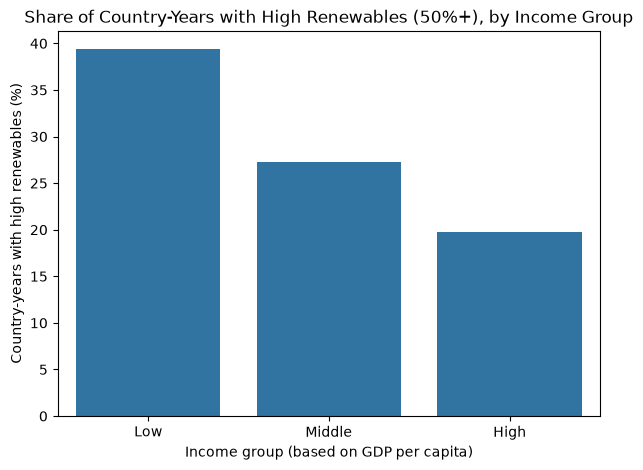

In [22]:
d = df.dropna(subset=["income_group", "high_renewables"])
prob = d.groupby("income_group", observed=True)["high_renewables"].mean() * 100

plt.figure(figsize=(7, 5))
sns.barplot(x=prob.index, y=prob.values)
plt.title("Share of Country-Years with High Renewables (50%+), by Income Group")
plt.xlabel("Income group (based on GDP per capita)")
plt.ylabel("Country-years with high renewables (%)")
plt.show()

**Why this chart:** A bar chart makes it easy to compare three groups.
**What it shows:** The share of country-years with high renewables (50% or
more) falls as income rises: about 39% in the Low group, 27% in the Middle
group, and 20% in the High group.
**Insight:** If I pick a country-year at random, a poorer one is about twice
as likely as a rich one to have high renewables.
**Conclusion:** Higher income goes with a lower chance of high renewables in
this data. This is an association, not proof of cause.

Chart 2: Scatter plot with a trend line

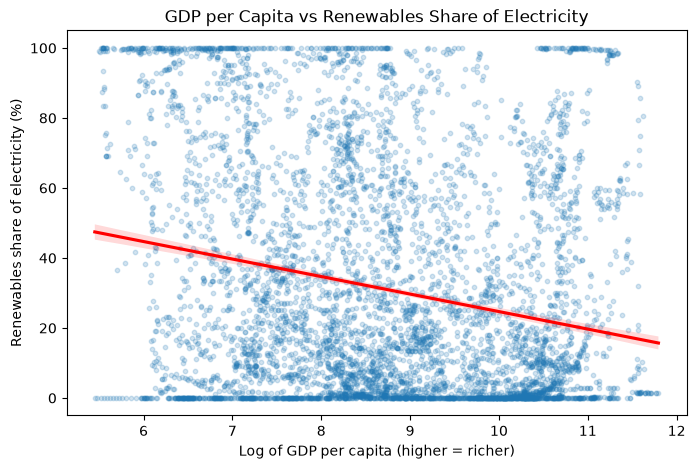

In [23]:
d = df.dropna(subset=["log_gdp_per_capita", "renewables_share_elec"])

plt.figure(figsize=(8, 5))
sns.regplot(data=d, x="log_gdp_per_capita", y="renewables_share_elec",
            scatter_kws={"alpha": 0.2, "s": 10}, line_kws={"color": "red"})
plt.title("GDP per Capita vs Renewables Share of Electricity")
plt.xlabel("Log of GDP per capita (higher = richer)")
plt.ylabel("Renewables share of electricity (%)")
plt.show()

**Why this chart:** A scatter plot shows the relationship between two numbers.
**What it shows:** The trend line slopes down. Richer country-years tend to
have a lower renewables share, but the dots are widely spread.
**Insight:** Wealth alone explains little of the differences in renewables
share. Many country-years sit at 0% or 100%.
**Conclusion:** There is a weak negative link. I will test it formally in the
hypothesis tests.

Chart 3: Correlation heatmap

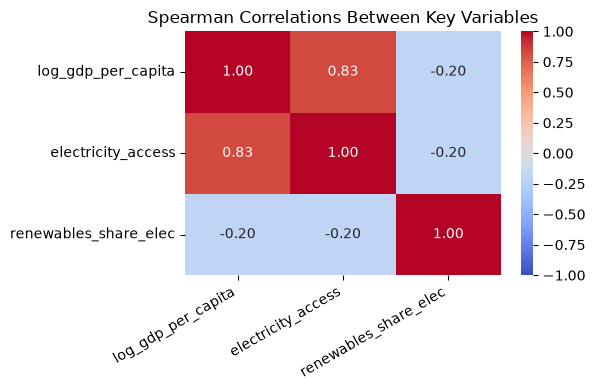

In [26]:
cols = ["log_gdp_per_capita", "electricity_access", "renewables_share_elec"]
corr = df[cols].corr(method="spearman")

plt.figure(figsize=(6, 4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Spearman Correlations Between Key Variables")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Why this chart:** A heatmap shows all correlations at once.
**What it shows:** Log GDP per capita and electricity access have a strong
positive Spearman correlation of 0.83. Renewables share has a weak negative
correlation of -0.20 with both.
**Insight:** Richer country-years tend to have more electricity access, but
a lower renewables share.
**Conclusion:** My first expectation is supported. For renewables, I found a
weak negative link. Correlation does not prove causation.

### Phase 5: Three hypothesis tests ###
The first design decision: independence

My joined data has one row per country per year, so the same country appears many times. Most tests assume each row is an independent observation, and repeated years of one country are not. If we ignore this, our p-values would look more convincing than they should.

So for the tests, we use one row per country: the most recent year in which that country has GDP per capita, electricity access and renewables share all measured. This is a subset of my joined data, and the joined dataset stays as it is. We state this choice in the notebook.

Cell 1: Build the one-row-per-country table

In [27]:
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

need = ["gdp_per_capita", "electricity_access", "renewables_share_elec"]
complete = df.dropna(subset=need)

latest = complete.sort_values("year").groupby("iso_code").tail(1).copy()

latest["income_group"] = pd.qcut(latest["gdp_per_capita"], q=3, labels=["Low", "Middle", "High"])
latest["high_renewables"] = (latest["renewables_share_elec"] >= 50).astype(int)
latest["full_access"] = (latest["electricity_access"] >= 99).astype(int)

print("Countries:", latest.shape[0], "| keys unique:", latest["iso_code"].is_unique)
print(latest["year"].describe())
print(latest["income_group"].value_counts())
print(latest[["high_renewables", "full_access"]].mean().round(3))

Countries: 198 | keys unique: True
count     198.000000
mean     2023.191919
std         1.454395
min      2011.000000
25%      2023.000000
50%      2023.500000
75%      2024.000000
max      2024.000000
Name: year, dtype: float64
income_group
Low       66
Middle    66
High      66
Name: count, dtype: int64
high_renewables    0.328
full_access        0.636
dtype: float64


### Independence and the country-level table

The joined data has one row per country per year, so the same country
appears many times. To keep the tests fair, I used one row per country: the
most recent year with GDP per capita, electricity access and renewables share
all measured. This gives 198 countries, mostly from 2023 and 2024. I divided
them into three income groups of 66 countries each.

Rules for reading the results

The significance level is 0.05. If p is below 0.05, we reject H₀. Otherwise we fail to reject H₀.

A p-value is not the probability that H₀ is true. It is how likely we are to see a result this extreme if H₀ were true.

Multiple tests: With three tests, the chance of at least one false alarm rises. A stricter check divides 0.05 by 3 to get about 0.017. We will look at both.


*** Test 1: Independent-samples t-test***

Research question: Do low-income and high-income countries differ in the average renewables share of electricity?

-H₀: The mean renewables share is the same in the Low and High groups.

-H₁: The means are different (two-sided).
* Why this test: We compare the average of a number between two separate groups.
* Assumptions: The countries are independent (one row each). The groups are large enough that the mean behaves well. We use Welch’s version, which does not assume equal variances. As a backup, the Mann-Whitney test does not assume a bell-shaped distribution.

In [28]:
low = latest.loc[latest["income_group"] == "Low", "renewables_share_elec"]
high = latest.loc[latest["income_group"] == "High", "renewables_share_elec"]

print("n:", len(low), len(high))
print("Mean:", round(low.mean(), 1), round(high.mean(), 1))
print("Median:", round(low.median(), 1), round(high.median(), 1))
print("Std:", round(low.std(), 1), round(high.std(), 1))
print("Shapiro p (Low, High):", stats.shapiro(low)[1], stats.shapiro(high)[1])

t, p = stats.ttest_ind(low, high, equal_var=False)
print("Welch t =", round(t, 3), "| p =", p)
print("Mann-Whitney p =", stats.mannwhitneyu(low, high, alternative="two-sided")[1])

n: 66 66
Mean: 45.0 35.9
Median: 34.2 28.0
Std: 34.5 31.6
Shapiro p (Low, High): 4.431311024221954e-05 4.84388966523594e-05
Welch t = 1.582 | p = 0.116138962905573
Mann-Whitney p = 0.12900251007580155


### Test 1: Independent-samples t-test (Welch)

**Research question:** Do low-income and high-income countries differ in
renewables share of electricity?
**H0:** The mean renewables share is the same in both groups.
**H1:** The means are different.
**Why this test:** I compare the average of a number between two separate
groups. I used Welch's version because it does not assume equal variances.
**Assumptions checked:** Countries are independent (one row each). The data
is not bell-shaped (Shapiro p < 0.001), but with 66 per group the test is
fairly robust, and the Mann-Whitney test agrees.
**Result:** Mean 45.0 (Low) vs 35.9 (High). t = 1.582, p = 0.116.
**Significance level:** 0.05. **Decision:** Fail to reject H0.
**Interpretation:** Low-income countries had a higher average in my sample,
but the difference is small compared with how widely the values vary, and it
could be due to chance. A p-value is not the probability that H0 is true. It
tells me how surprising this result would be if H0 were true.
**Practical meaning:** Income level alone does not reliably predict renewables
share, so planners should look at other factors too.

**Test 2: Chi-square test of independence**

Research question: Is having high renewables (50% or more) independent of income group?

H₀: High-renewables status and income group are independent.

H₁: They are related.

* Why this test: Both variables are categories, and chi-square compares the counts we see with the counts we would expect if there were no link.
* Assumptions: Independent countries, and expected counts of at least 5 in each cell.

In [29]:
table = pd.crosstab(latest["income_group"], latest["high_renewables"])
print(table)

chi2, p, dof, expected = stats.chi2_contingency(table)
print("chi2 =", round(chi2, 3), "| df =", dof, "| p =", p)
print("Smallest expected count:", round(expected.min(), 1))

high_renewables   0   1
income_group           
Low              40  26
Middle           49  17
High             44  22
chi2 = 2.794 | df = 2 | p = 0.2473111162492815
Smallest expected count: 21.7


### Test 2: Chi-square test of independence

**Research question:** Is having high renewables (50%+) independent of
income group?
**H0:** They are independent. **H1:** They are related.
**Why this test:** Both variables are categories, and chi-square compares
observed counts with the counts expected if there were no link.
**Assumptions checked:** Independent countries, and every expected count is
at least 5 (the smallest is 21.7).
**Result:** High renewables: 39% of Low, 26% of Middle, 33% of High income
countries. chi-square = 2.794, df = 2, p = 0.247.
**Significance level:** 0.05. **Decision:** Fail to reject H0.
**Interpretation:** The differences between groups are small enough that
chance could explain them.
**Practical meaning:** A country's income group is not a reliable guide to
whether it gets half or more of its electricity from renewables.

**Test 3: A/B-style comparison with a two-proportion Z-test**
Research question: Do countries with high renewables (Group A) have a different share with full electricity access (99% or more) than other countries (Group B)?

H₀: The share with full access is the same in both groups.

H₁: The shares are different.

* Why this test: We compare two proportions between two groups.
* Assumptions: Independent countries, and at least 5 expected successes and failures in each group.

Important: The groups occur naturally. We did not assign countries to them. A difference would show an association and would not prove that renewables cause anything.

In [30]:
a = latest.loc[latest["high_renewables"] == 1, "full_access"]
b = latest.loc[latest["high_renewables"] == 0, "full_access"]
counts = np.array([a.sum(), b.sum()])
nobs = np.array([len(a), len(b)])

print("Group sizes (A, B):", nobs)
print("Full-access counts:", counts)
print("Proportions:", (counts / nobs).round(3))

pooled = counts.sum() / nobs.sum()
print("Expected successes:", (nobs * pooled).round(1), "| failures:", (nobs * (1 - pooled)).round(1))

z, p = proportions_ztest(counts, nobs)
print("z =", round(z, 3), "| p =", p)

Group sizes (A, B): [ 65 133]
Full-access counts: [36 90]
Proportions: [0.554 0.677]
Expected successes: [41.4 84.6] | failures: [23.6 48.4]
z = -1.687 | p = 0.09152269541648472


### Test 3: A/B-style comparison (two-proportion Z-test)

**Research question:** Do countries with high renewables (Group A) and
other countries (Group B) differ in the share with full electricity access?
**H0:** The shares are equal. **H1:** They are different.
**Why this test:** I compare two proportions between two groups.
**Groups:** The groups occur naturally. Countries were not randomly assigned,
so a difference would not prove that renewables cause anything.
**Assumptions checked:** Independent countries, and expected successes and
failures are all above 5.
**Result:** Full access: 55.4% (36 of 65) in Group A and 67.7% (90 of 133)
in Group B. z = -1.687, p = 0.092.
**Significance level:** 0.05. **Decision:** Fail to reject H0.
**Interpretation:** Group A had a lower share in my sample, but the gap could
be due to chance. I do not claim a difference.
**Practical meaning:** A high renewables share does not by itself guarantee
or prevent full access, so access programs need their own planning.

Failing to reject H₀ does not prove there is no difference. With 66 countries per group, the tests can only detect fairly large differences.
The earlier country-year chart looked stronger. The bar chart showed 39%, 27% and 20%. The country-level table shows 39%, 26% and 33%, so the High group is different. The two use different groups, and the first counted every country-year, so repeated years of the same country made the pattern look stronger. This is why we used one row per country.

Cell 5: save the results for the app

In [32]:
t1 = stats.ttest_ind(low, high, equal_var=False)
chi = stats.chi2_contingency(table)
z3 = proportions_ztest(counts, nobs)

res = pd.DataFrame({
    "test": ["Welch t-test: renewables share, Low vs High income",
             "Chi-square: income group vs high renewables",
             "Two-proportion z-test: full access, high vs other renewables"],
    "statistic": [t1.statistic, chi[0], z3[0]],
    "p_value": [t1.pvalue, chi[1], z3[1]],
})
res["decision_at_0.05"] = np.where(res["p_value"] < 0.05, "Reject H0", "Fail to reject H0")

res.to_csv("../data/processed/hypothesis_results.csv", index=False)
latest.to_csv("../data/processed/country_latest.csv", index=False)
print(res)

                                                test  statistic   p_value  \
0  Welch t-test: renewables share, Low vs High in...   1.581822  0.116139   
1        Chi-square: income group vs high renewables   2.794216  0.247311   
2  Two-proportion z-test: full access, high vs ot...  -1.687420  0.091523   

    decision_at_0.05  
0  Fail to reject H0  
1  Fail to reject H0  
2  Fail to reject H0  


In [31]:
print(latest[latest["iso_code"] == "KEN"][["country", "year", "gdp_per_capita",
      "electricity_access", "renewables_share_elec", "income_group"]])

     country  year  gdp_per_capita  electricity_access  renewables_share_elec  \
5402   Kenya  2024       1858.8765                77.0                 91.907   

     income_group  
5402          Low  


### Phase 6: final charts and the Streamlit app ###

What the Kenya row shows

For 2024, Kenya has GDP per capita of about 1,859 (constant 2015 US$), electricity access of 77.0%, and a renewables share of 91.9%. It falls in your Low income group. Its renewables share is far above that group’s average of 45.0, but its electricity access is below full access. That makes Kenya a useful example for the presentation. It shows that a high renewables share and full access are separate things. One country is an illustration and is not statistical evidence.

Step 1: Two final charts in the notebook

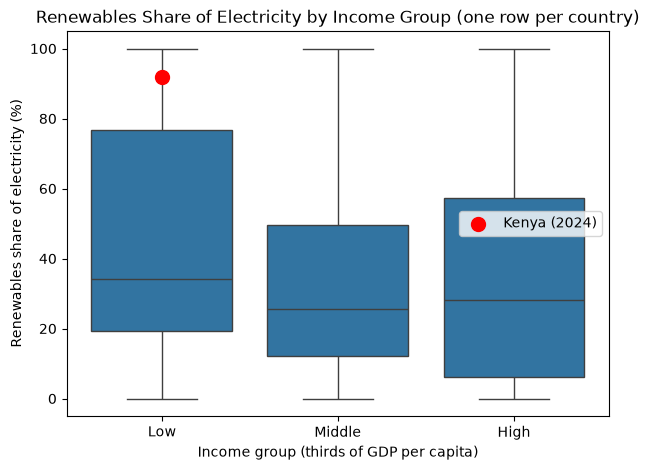

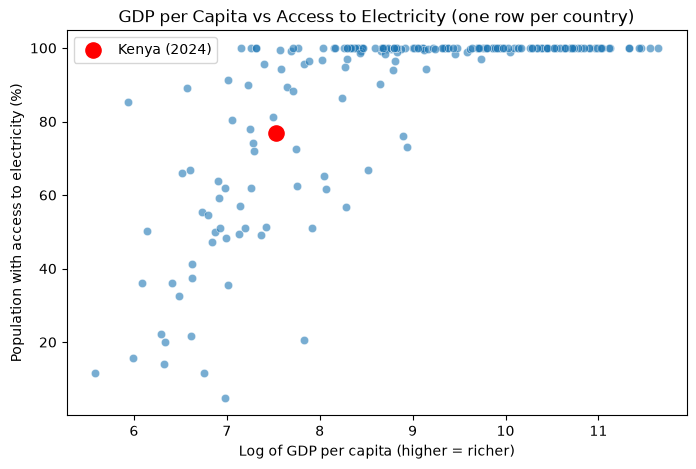

In [33]:
order = ["Low", "Middle", "High"]
ken = latest[latest["iso_code"] == "KEN"].iloc[0]

# Chart A: renewables share by income group, Kenya marked
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=latest, x="income_group", y="renewables_share_elec", order=order, ax=ax)
ax.scatter(order.index(ken["income_group"]), ken["renewables_share_elec"],
           color="red", s=100, zorder=5, label="Kenya (2024)")
ax.set_title("Renewables Share of Electricity by Income Group (one row per country)")
ax.set_xlabel("Income group (thirds of GDP per capita)")
ax.set_ylabel("Renewables share of electricity (%)")
ax.legend()
plt.show()

# Chart B: GDP vs electricity access, Kenya marked
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=latest, x="log_gdp_per_capita", y="electricity_access", alpha=0.6, ax=ax)
ax.scatter(ken["log_gdp_per_capita"], ken["electricity_access"],
           color="red", s=120, zorder=5, label="Kenya (2024)")
ax.set_title("GDP per Capita vs Access to Electricity (one row per country)")
ax.set_xlabel("Log of GDP per capita (higher = richer)")
ax.set_ylabel("Population with access to electricity (%)")
ax.legend()
plt.show()